# Laboratorium 2 - Debuggowanie programów w Python, mapowanie danych, przetwarzanie danych

# Debuggowanie w PyCharm

Kod numer 1, wklej kod do nowego pliku w Pycharm i uruchom. Vowel to samogłoski a consonants to spółgłoski.

In [1]:
def count_vowels(word):
    vowels = ['a', 'e', 'i', 'o', 'u']
    count = 0
    for char in word:
        if char in vowels:
            count += 1
    return count


def count_consonants(word):
    vowels = ['a', 'e', 'i', 'o', 'u']
    count = 0
    for char in word:
        if char.isalpha() and char not in vowels:
            count += 1
    return count


def main():
    word = input("Enter a word: ")
    vowels = count_vowels(word)
    consonants = count_consonants(word)
    print("The word", word, "contains", vowels, "vowels and", consonants, "consonants.")


# User needs to debug the error below
main()

Enter a word: Ala
The word Ala contains 1 vowels and 2 consonants.


Uruchom kod dla słowa “Ala”. Zwrócona odpowiedź nie jest poprawna. Znajdź błąd. Aby znaleźć błąd w programie można posłużyć się procesem debuggowania, czyli uruchamiania programu krok po kroku w celu sprawdzenia jego działania w kolejnych iteracjach.

W celu uruchomienia programu w trybie debuggowania w Pycharm należy wybrać zamiast zielonej strzałki, ikonkę zielonego robaczka, lub też kliknąć na pliku prawym przyciskiem myszy i wybrać opcję **Debug** (powinna być zaraz pod Run).

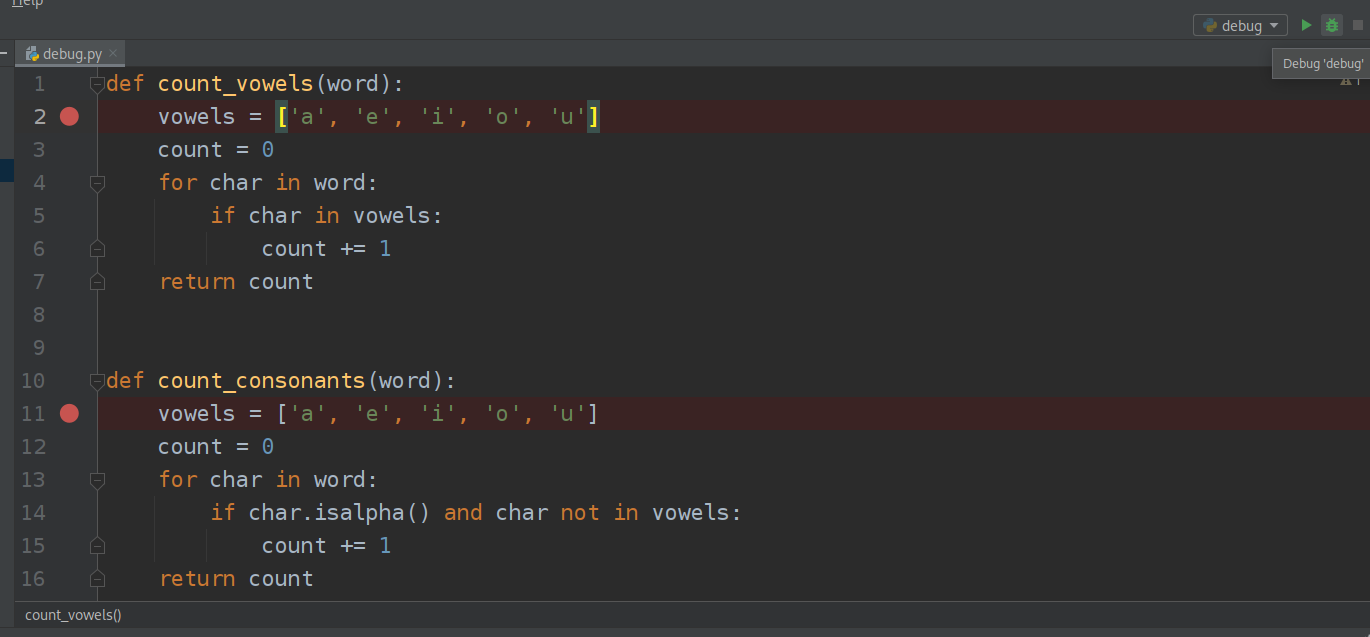

Z debuggowaniem związane jest pojęcie breakpointa, czyli punktu zatrzymania wykonania. Aby dodać breakpoint w PyCharm należy nacisnąć obok numeru linii programu tak by pojawiła się czerwona kropka, ona symbolizuje właśnie breakpoint.

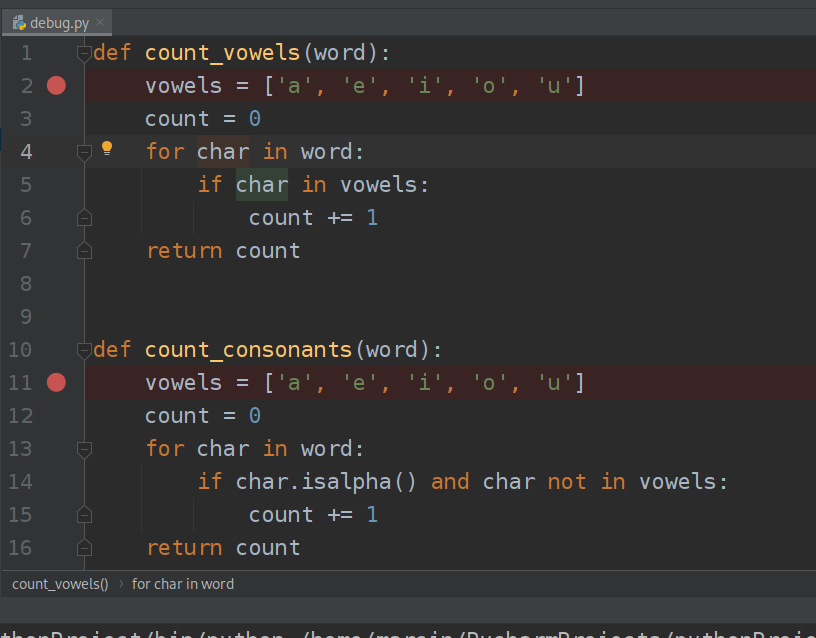

Gdy program osiągnie breakpoint zatrzyma swoje wykonanie i w edytorze kodu zobaczymy podświetloną linię - znaczy to, że program wykonał wszystkie operacje do tej linii (**ale nie wliczając jej**).

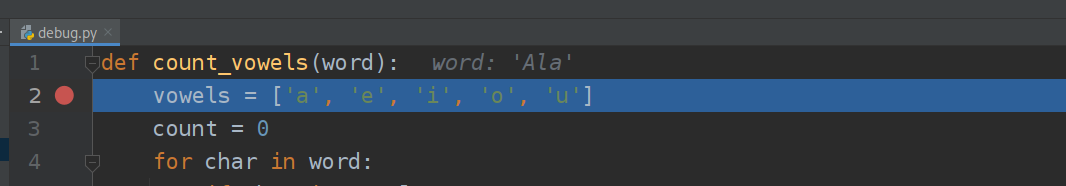

Dodatkowo w menu podręcznym na dole ekranu pojawić powinno się okno z podglądem wartości zmiennych w danym punkcie wykonania.

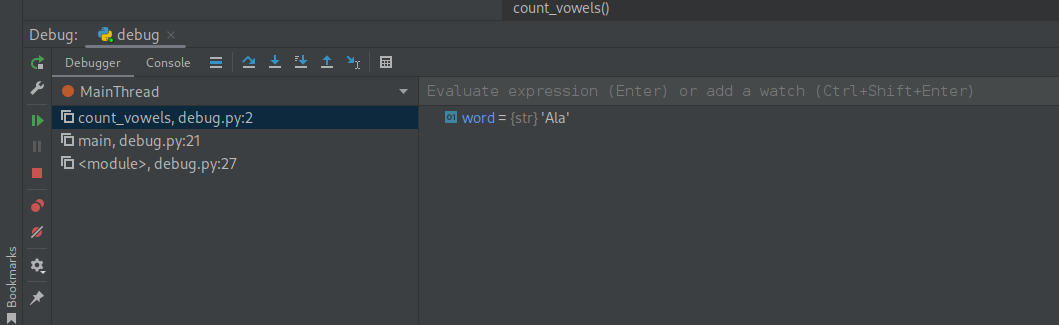

Od tego momentu możemy wykonać trzy operacje

> **F9** - wznawia uruchomienie programu do osiągnięcia następnego breakpointa

> **F8** - uruchamia kolejną linijkę programu na poziomie na którym się znajdujemy (czyli obecnie zaznaczoną)
>
> **F7** - wykonuje kolejną linię programu (czyli w przypadku wykonania funkcji wejdzie do środka metody i wykona pierwszą linijkę tej metody a w przypadku prostej operacji wykona poświetloną właśnie linijkę.

Przetestuj działanie dodając breakpoint w 21 linijce programu i wybierając raz **F7** raz **F8** raz **F9**.

Następnie ustaw breakpoint w 11 linijce programu i przejdź przez pętle linijka po linijce, czy widzisz gdzie jest błąd w zliczaniu spółgłosek?

Czasem w sprawdzaniu co się dzieje pomaga nam opcja Evaluate expression gdzie możemy wpisać dowolny kod i zobaczyć jego wynik.

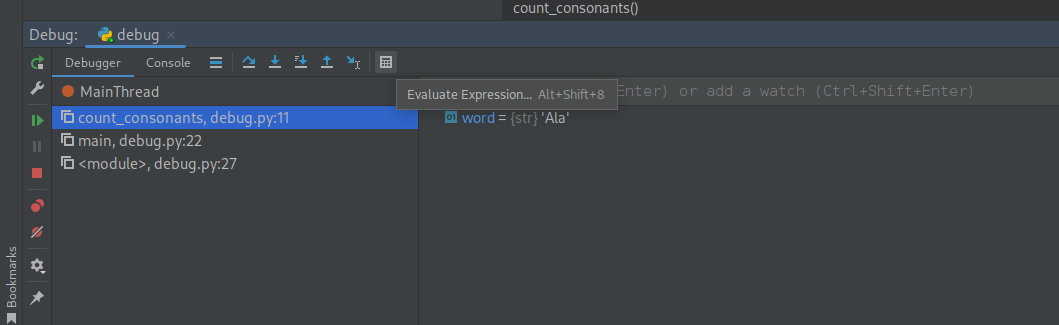

Uwaga! Dostępna jest ona oczywiście tylko w trybie debuggowania! Wybierz evaluate expression i wpisz w środek

> ‘A’.isalpha()

> ‘A’ not in vowels

Zauważ, że aby evaluator wiedział co oznacza lista vowels muszę wykonaniem programu dojśc do miejsca gdzie lista ta była zadeklarowana!

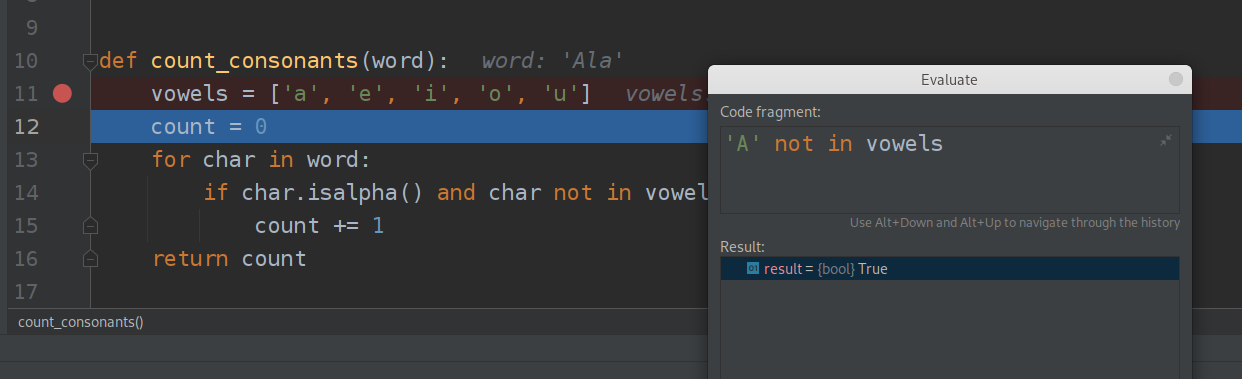

Zauważ też że ewaluator może wpływać na zmienne w działającym programie, może wiec zmieniać jego wykonanie i stan (nawet po wyjściu z jego okienka), używaj go więc rozważnie!

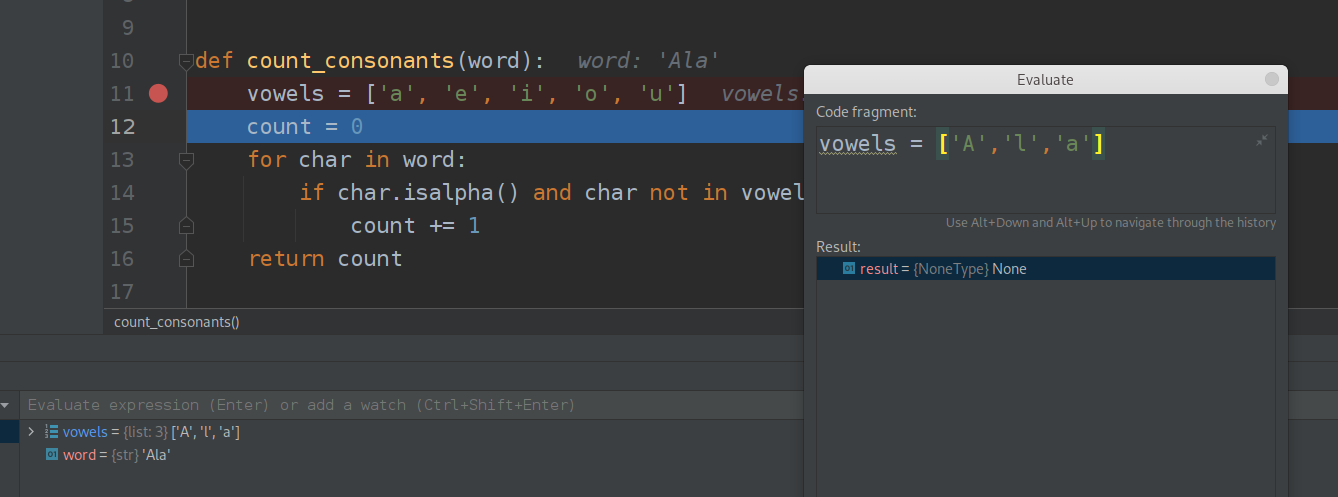

Jak widać błędem było nieuwględnienie wielkich liter w przetwarzaniu. Popraw bład i uruchom program raz jeszcze.

Gdy klikniemy prawym przyciskiem na breakpoint pojawi się nam okno opcji dla breakpointa. Możemy ustawić w nim warunek - wtedy program zatrzyma się w tym miejscu tylko gdy warunek będzie spełniony. Druga istotna dla nas później opcja to możliwość zatrzymania tylko wątku który dotarł do tego miejsca lub wszystkich wątków programu (będzie to wykorzystane na kolejnych zajęciach).

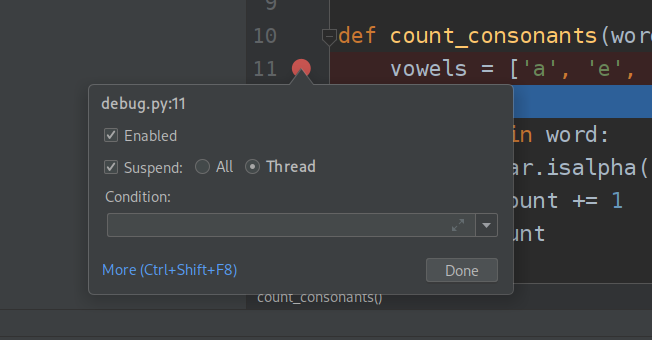

> **Zrób to sam!**
>
> Popraw funkcję `count_consonants` tak, by poprawnie zliczała także wielkie litery, np. dla słowa **“Ala”** program powinien wypisać *2 vowels and 1 consonants*. Czy funkcja `count_vowels` ma ten sam błąd?

Kod 2: Ten kod używa zmodyfikowanego algorytmu szybkiego wyboru (*quickselect*), aby znaleźć medianę bez sortowania listy. Funkcja `find_median()` wielokrotnie dzieli listę na elementy, które są mniejsze, równe lub większe niż losowo wybrany element przestawny (*pivot*), aż znajdzie element, który pojawia się na środku listy.

Medianą listy `[7, 1, 5, 3, 9, 2, 8]` jest **5**. Uruchom program kilka razy i porównaj wyniki.

In [2]:
import random


def quickselect(lst, k):
    pivot = random.choice(lst)
    lows = [x for x in lst if x < pivot]
    pivots = [x for x in lst if x == pivot]
    highs = [x for x in lst if x > pivot]

    if k < len(lows):
        return quickselect(lows, k)
    elif k < len(lows) + len(pivots):
        return pivot
    else:
        return quickselect(highs, k - len(lows))


def find_median(lst):
    return quickselect(lst, len(lst) // 2)


random.seed(8)  # ustalone ziarno, aby wynik był powtarzalny
dane = [7, 1, 5, 3, 9, 2, 8]
for proba in range(5):
    print("Mediana:", find_median(dane))

Mediana: 8
Mediana: 8


IndexError: Cannot choose from an empty sequence

Program raz zwraca zły wynik, a raz kończy się wyjątkiem `IndexError`. Ponieważ *pivot* jest losowy, błąd pojawia się tylko dla niektórych przebiegów. To dobry przykład na **breakpoint warunkowy**: ustaw breakpoint w linii `pivot = random.choice(lst)` z warunkiem `len(lst) == 0` lub `k >= len(lst)` i sprawdź w oknie zmiennych, jak doszło do tej sytuacji. Przejdź (**F7**) wywołania rekurencyjne i obserwuj wartości `k`, `lows`, `pivots` oraz `highs`.

> **Zrób to sam!**
>
> Znajdź i popraw błąd w funkcji `quickselect`. Podpowiedź: ile elementów odrzucamy, gdy przechodzimy do listy `highs`? Po poprawce program powinien pięć razy wypisać `Mediana: 5`, niezależnie od ziarna `random.seed`.

# Przetwarzanie i generowanie danych

## Iteratory

Iterator to obiekt, który zwraca kolejne elementy na żądanie (funkcja `next()`), a gdy elementów zabraknie, zgłasza wyjątek `StopIteration`. Pętla `for` w Pythonie robi dokładnie to samo: wywołuje `iter()` na kolekcji, a potem `next()` aż do `StopIteration`.

Sprawdź co stanie się w sytuacji, gdy dojdziemy do końca iteratora.

In [3]:
L = [1, 2, 3]
it = iter(L)
print(it)

print(it.__next__())
print(next(it))
print(it.__next__())
print(next(it))

1
2
3


StopIteration: 

Funkcja `next()` przyjmuje opcjonalną wartość domyślną, zwracaną zamiast zgłaszania wyjątku. Iterator jest **jednorazowy** - po wyczerpaniu nie zaczyna od początku.

In [4]:
L = [1, 2, 3]
it = iter(L)
print(list(it))
print(list(it))
print(next(it, "koniec danych"))

[1, 2, 3]
[]
koniec danych


Gdy wywołasz `iter()` na słowniku, otrzymasz iterator, który przegląda klucze słownika (od Pythona 3.7 w kolejności dodawania):

In [5]:
miesiace = {'Jan': 'Sty', 'Feb': 'Lut', 'Mar': 'Mar', 'Apr': 'Kwi', 'May': 'Maj', 'Jun': 'Cze',
            'Jul': 'Lip', 'Aug': 'Sie', 'Sep': 'Wrz', 'Oct': 'Paź', 'Nov': 'Lis', 'Dec': 'Gru'}

it = iter(miesiace)

for _ in range(5):
    klucz = next(it)
    print(klucz, miesiace[klucz])

Jan Sty
Feb Lut
Mar Mar
Apr Kwi
May Maj


Słowniki posiadają metody `keys()`, `values()` i `items()`, które zwracają **widoki** (ang. *views*) - obiekty, po których można iterować, i które zawsze odzwierciedlają aktualną zawartość słownika. Iterator uzyskamy z widoku funkcją `iter()`.

In [6]:
miesiace = {'Jan': 'Sty', 'Feb': 'Lut', 'Mar': 'Mar'}

wartosci = miesiace.values()
pary = miesiace.items()
print(wartosci)
print(pary)

miesiace['Apr'] = 'Kwi'          # widok widzi zmianę w słowniku
print(wartosci)

it = iter(pary)
print(next(it))
for ang, pol in it:              # pętla for kontynuuje od miejsca, w którym skończył next()
    print(ang, '->', pol)

dict_values(['Sty', 'Lut', 'Mar'])
dict_items([('Jan', 'Sty'), ('Feb', 'Lut'), ('Mar', 'Mar')])
dict_values(['Sty', 'Lut', 'Mar', 'Kwi'])
('Jan', 'Sty')
Feb -> Lut
Mar -> Mar
Apr -> Kwi


### Iterator na listę

Możemy zamienić obiekt iteratora na listę lub krotkę korzystając z funkcji `list()` oraz `tuple()`.

In [7]:
L = [1, 2, 3]
iterator = iter(L)
print(list(iterator))
iterator = iter(L)
print(tuple(iterator))

[1, 2, 3]
(1, 2, 3)


### Własny iterator

Możemy definiować własne klasy iteratorów - wystarczy zaimplementować metodę `__next__()` (klasa bazowa `Iterator` dostarcza `__iter__()`). Poniżej licznik, który jest **nieskończonym** iteratorem, oraz odliczanie, które kończy się wyjątkiem `StopIteration`:

In [8]:
from collections.abc import Iterator


class Licznik(Iterator):
    def __init__(self, start=0, krok=1):
        self.wartosc = start - krok
        self.krok = krok

    def __next__(self):
        self.wartosc += self.krok
        return self.wartosc


class Odliczanie(Iterator):
    def __init__(self, od):
        self.biezaca = od

    def __next__(self):
        if self.biezaca <= 0:
            raise StopIteration
        self.biezaca -= 1
        return self.biezaca + 1


licznik = Licznik(10, 5)
print(next(licznik), next(licznik), next(licznik))

for i in Odliczanie(3):
    print(i, end=' ')
print('start!')

10 15 20
3 2 1 start!


# Generatory

Funkcja zawierająca słowo kluczowe **yield** jest funkcją generatora. Kompilator kodu bajtowego Pythona identyfikuje go, co w rezultacie powoduje inną kompilację funkcji. Wywołanie funkcji generatora zwraca generator obsługujący protokół iteratora, a nie pojedynczą wartość. Kod funkcji wykonuje się dopiero przy kolejnych wywołaniach `next()` i zatrzymuje na każdym `yield`.

Porównaj listę par utworzoną przez *list comprehension* z generatorem tych samych par:

In [9]:
seq1 = 'ABC'
seq2 = (1, 2, 3)
print([(x, y) for x in seq1 for y in seq2])

[('A', 1), ('A', 2), ('A', 3), ('B', 1), ('B', 2), ('B', 3), ('C', 1), ('C', 2), ('C', 3)]


In [10]:
def generate_pairs(A, B):
    for x in A:
        for y in B:
            yield (x, y)


gen = generate_pairs('ABC', (1, 2, 3))
print(gen)
print(next(gen))
print(next(gen))
print(next(gen))
print(next(gen))
print(list(gen))   # pozostałe elementy

<generator object generate_pairs at 0x7f93e72f2c00>
('A', 1)
('A', 2)
('A', 3)
('B', 1)
[('B', 2), ('B', 3), ('C', 1), ('C', 2), ('C', 3)]


Generatory są **leniwe** - nie przechowują wszystkich elementów w pamięci, tylko wyliczają kolejny element wtedy, gdy jest potrzebny. Wyrażenie generatorowe zapisujemy jak *list comprehension*, ale w nawiasach okrągłych. Porównaj zajętość pamięci:

In [11]:
import sys

kwadraty_lista = [x * x for x in range(1_000_000)]
kwadraty_gen = (x * x for x in range(1_000_000))

print(f"lista:     {sys.getsizeof(kwadraty_lista):>10,} B")
print(f"generator: {sys.getsizeof(kwadraty_gen):>10,} B")
print("suma:", sum(kwadraty_gen))

lista:      8,448,728 B
generator:        200 B
suma: 333332833333500000


Generator może też być **nieskończony** - jest wtedy naturalnym modelem strumienia danych. Funkcja `islice` z modułu `itertools` pozwala pobrać z niego tylko kilka pierwszych elementów:

In [12]:
from itertools import islice


def fibonacci():
    a, b = 0, 1
    while True:
        yield a
        a, b = b, a + b


print(list(islice(fibonacci(), 15)))

[0, 1, 1, 2, 3, 5, 8, 13, 21, 34, 55, 89, 144, 233, 377]


# List comprehension

List comprehension to elegancki sposób definiowania i tworzenia list na podstawie istniejących sekwencji. Składnia: `[wyrażenie for element in sekwencja]`. Działa dla dowolnego obiektu, po którym można iterować - listy, napisu, krotki czy generatora.

Operacje w list comprehension możesz zrobić za pomocą pętli. Jednak nie każdą pętlę można przepisać jako list comprehension. Są one jednak bardziej eleganckim i zwięzłym zapisem wielu akcji.

In [13]:
litery = [litera for litera in 'word']
print(litery)

['w', 'o', 'r', 'd']


In [14]:
parzyste = [x for x in range(20) if x % 2 == 0]
print(parzyste)

[0, 2, 4, 6, 8, 10, 12, 14, 16, 18]


Podwójny warunek logiczny (nested if)

In [15]:
num_list = [y for y in range(100) if y % 2 == 0 if y % 5 == 0]
print(num_list)

[0, 10, 20, 30, 40, 50, 60, 70, 80, 90]


Tutaj sprawdzamy:

```
Czy y jest podzielne przez 2?
Czy y jest podzielne przez 5?
```

Jeśli y spełnia oba warunki, y jest dołączane do `num_list`. Zwróć uwagę na różnicę między **filtrowaniem** (warunek `if` po `for ... in`) a **zmianą elementu** (wyrażenie `... if ... else ...` przed `for`) oraz na kolejność ich wykonywania:

In [16]:
num_list = ['A' if y % 20 == 0 else 'B' for y in range(100) if y % 2 == 0 if y % 5 == 0]
print(num_list)

num_list = [rr for rr in [10 if y % 25 == 0 else 7 for y in range(100)] if rr % 2 == 0 if rr % 5 == 0]
print(num_list)

['A', 'B', 'A', 'B', 'A', 'B', 'A', 'B', 'A', 'B']
[10, 10, 10, 10]


Zagnieżdżone pętle:

In [17]:
matrix = [[1, 2], [3, 4], [5, 6], [7, 8]]
transpose = [[row[i] for row in matrix] for i in range(2)]
print(transpose)

plaska = [x for row in matrix for x in row]
print(plaska)

[[1, 3, 5, 7], [2, 4, 6, 8]]
[1, 2, 3, 4, 5, 6, 7, 8]


Analogicznie tworzymy słowniki i zbiory (*dict / set comprehension*):

In [18]:
slowa = ["wątek", "proces", "strumień", "wątek", "kafka", "proces"]

dlugosci = {s: len(s) for s in slowa}
unikalne = {s.upper() for s in slowa}
print(dlugosci)
print(unikalne)

{'wątek': 5, 'proces': 6, 'strumień': 8, 'kafka': 5}
{'PROCES', 'STRUMIEŃ', 'KAFKA', 'WĄTEK'}


# Lambda

W Pythonie funkcja lambda jest funkcją anonimową, co oznacza, że jest **funkcją bez nazwy**. Może mieć dowolną liczbę argumentów, ale tylko jedno wyrażenie, które jest obliczane i zwracane. **Musi mieć wartość zwracaną**. Najprostsza lambda to funkcja identycznościowa.

In [19]:
ident = lambda x: x

print(ident(6))

6


Ponieważ funkcja lambda musi mieć wartość zwracaną dla każdego prawidłowego wejścia, nie możemy jej zdefiniować za pomocą **if** bez **else** - nie określamy wtedy, co zwrócimy, jeśli warunek będzie fałszywy. Spróbujmy zapisać lambdę, która zwraca liczbę tylko gdy jest ona dodatnia:

In [20]:
dodatnia = lambda x: x if (x > 0)

SyntaxError: expected 'else' after 'if' expression (2443560714.py, line 1)

Interpreter zgłasza błąd składni już przy definicji. Aby to poprawić, musimy określić, co zostanie zwrócone, jeśli warunek będzie fałszywy, tj. dopisać część **else**. W ten sposób otrzymamy wartość bezwzględną:

In [21]:
wartosc_bezwzgledna = lambda x: x if (x > 0) else -x

print(wartosc_bezwzgledna(6))
print(wartosc_bezwzgledna(-6))

6
6


In [22]:
maksimum = lambda a, b: a if (a > b) else b

print(maksimum(1, 2))
print(maksimum(10, 2))

2
10


**Uwaga!** Nie nadawaj zmiennym nazw funkcji wbudowanych (`abs`, `max`, `sum`, `list`, …). Po przypisaniu `max = lambda a, b: ...` wbudowana funkcja `max` przestaje być dostępna w całym notatniku (aż do restartu kernela).

Połączenie lambdy z *list comprehension*. W każdej iteracji wewnątrz *list comprehension* tworzymy nową funkcję lambda z domyślnym argumentem `arg=x` (gdzie `x` jest bieżącym elementem iteracji). Później, wewnątrz pętli `for`, wywołujemy każdy obiekt funkcji bez argumentów i uzyskujemy pożądaną wartość. Zatem `reszty_mod_5` przechowuje listę obiektów funkcji lambda.

In [23]:
reszty_mod_5 = [lambda arg=x: arg % 5 for x in range(1, 11)]

for funkcja in reszty_mod_5:
    print(funkcja(), end=' ')

1 2 3 4 0 1 2 3 4 0 

Po co domyślny argument? Lambda zapamiętuje **zmienną**, a nie jej wartość z chwili utworzenia (tzw. *late binding*). Bez domyślnego argumentu wszystkie funkcje odczytają `x` dopiero przy wywołaniu - czyli jego ostatnią wartość:

In [24]:
bez_domyslnego = [lambda: x % 5 for x in range(1, 11)]

for funkcja in bez_domyslnego:
    print(funkcja(), end=' ')

0 0 0 0 0 0 0 0 0 0 

Wywołanie lambdy przez inną lambdę. Lambda może przyjmować inną funkcję jako argument:

In [25]:
listy = [[2, 3, 4], [16, 1, 64, 4], [12, 3, 9, 6]]

sortuj_podlisty = lambda x: (sorted(i) for i in x)      # zwraca generator!

for podlista in sortuj_podlisty(listy):
    print(podlista)

zastosuj = lambda x, f: [y for y in f(x)]

print(zastosuj(listy, sortuj_podlisty))
print(zastosuj(listy, lambda x: (max(i) for i in x)))

[2, 3, 4]
[1, 4, 16, 64]
[3, 6, 9, 12]
[[2, 3, 4], [1, 4, 16, 64], [3, 6, 9, 12]]
[4, 64, 12]


Lambdy najczęściej przekazujemy jako argument `key` funkcji `sorted`, `min` i `max`:

In [26]:
studenci = [("Ola", 4.5), ("Jan", 3.0), ("Ewa", 5.0), ("Piotr", 4.0)]

print(sorted(studenci, key=lambda s: s[1], reverse=True))
print(max(studenci, key=lambda s: s[1]))
print(sorted(["kafka", "Flink", "spark", "Python"], key=str.lower))

[('Ewa', 5.0), ('Ola', 4.5), ('Piotr', 4.0), ('Jan', 3.0)]
('Ewa', 5.0)
['Flink', 'kafka', 'Python', 'spark']


# Zip

Połączenie kilku list argumentów w jedną listę krotek może być trudne. Na szczęście Python udostępnia funkcję `zip`. Łączy ona **N** sekwencji w jeden iterator krotek (każda krotka zawiera N elementów - po jednym z każdej sekwencji).

In [27]:
a = [1, 2, 3, 4, 5]
b = [6, 7, 8, 9, 10]
c = [11, 12, 13, 14, 15]

args = zip(a, b, c)
print(args)
print(list(args))

[(1, 6, 11), (2, 7, 12), (3, 8, 13), (4, 9, 14), (5, 10, 15)]


`zip` kończy działanie na **najkrótszej** sekwencji. Od Pythona 3.10 parametr `strict=True` zamienia ciche obcięcie danych na błąd:

In [28]:
czujniki = ["c1", "c2", "c3"]
odczyty = [21.5, 22.0]

print(dict(zip(czujniki, odczyty)))
print(list(zip(czujniki, odczyty, strict=True)))

{'c1': 21.5, 'c2': 22.0}


ValueError: zip() argument 2 is shorter than argument 1

Operator `*` „rozpakowuje” listę na argumenty, dlatego `zip(*macierz)` transponuje macierz, a `zip(*pary)` rozdziela listę par na dwie sekwencje:

In [29]:
matrix = [[1, 2], [3, 4], [5, 6], [7, 8]]
print(list(zip(*matrix)))

pary = [("Jan", 3.0), ("Ola", 4.5), ("Ewa", 5.0)]
imiona, oceny = zip(*pary)
print(imiona, oceny)

[(1, 3, 5, 7), (2, 4, 6, 8)]
('Jan', 'Ola', 'Ewa') (3.0, 4.5, 5.0)


# Filter

Funkcja `filter()` zatrzymuje tylko te elementy, dla których funkcja zwraca wartość **True**, a usuwa wszystkie, dla których zwraca **False**.

`filter` przyjmuje dwa argumenty: funkcję i obiekt, po którym można iterować. Podobnie jak `map` i `zip` zwraca leniwy iterator.

In [30]:
li = [5, -5, 2, -2, 0, 62, -77, 23, 73, -61]

final_list = list(filter(lambda x: x > 0, li))
print(final_list)

[5, 2, 62, 23, 73]


# Map

Funkcja `map()` w Pythonie przyjmuje jako argument funkcję i jedną lub więcej sekwencji argumentów. Działa podobnie do *list comprehension*: zwraca iterator z wynikami funkcji wywołanej dla każdego elementu wejściowego. Przykłady:

In [31]:
li = [5, -5, 2, -2, 0, 62, -77, 23, 73, -61]

final_list = list(map(lambda x: x * 2, li))
print(final_list)

[10, -10, 4, -4, 0, 124, -154, 46, 146, -122]


In [32]:
countries = ['poland', 'france', 'spain']

uppered_countries = list(map(str.upper, countries))     # zamiast lambda c: c.upper()
print(uppered_countries)

['POLAND', 'FRANCE', 'SPAIN']


Przypadek większej liczby argumentów oraz wykorzystania funkcji nazwanej zamiast lambdy:

In [33]:
def add(x, y):
    """Return the sum of the two arguments"""
    return x + y


a = [1, 2, 3, 4, 5]
b = [6, 7, 8, 9, 10]

result = map(add, a, b)
print(list(result))

[7, 9, 11, 13, 15]


# Reduce

Funkcja `reduce()` w Pythonie przyjmuje jako argument funkcję dwuargumentową i sekwencję, a zwraca jedną, zredukowaną wartość. Funkcja `reduce()` należy do modułu `functools`.

In [34]:
from functools import reduce

li = [1, 2, 3, 4, 5, 6]
suma = reduce(lambda x, y: x + y, li)
print(suma)

21


W tym wypadku wynik poprzedniego przetwarzania jest dodawany do kolejnego itd. (((((1+2)+3)+4)+5)+6). Lambda w `reduce` powinna przyjmować dwa argumenty: dotychczasowy wynik (*akumulator*) i kolejny element. Trzeci, opcjonalny argument to wartość początkowa akumulatora - dzięki niemu `reduce` działa również dla pustej sekwencji i może zwracać inny typ niż elementy:

In [35]:
from functools import reduce

slowa = ["map", "filter", "reduce", "zip", "lambda"]

najdluzsze = reduce(lambda acc, s: s if len(s) > len(acc) else acc, slowa)
print(najdluzsze)

licznik_liter = reduce(lambda acc, s: acc + len(s), slowa, 0)
print(licznik_liter)

print(reduce(lambda acc, s: acc + len(s), [], 0))

filter
24
0


# Przetwarzanie strumieniowe w Pythonie

Na wykładzie porównywaliśmy przetwarzanie **wsadowe** (dane zbierane w partie i przetwarzane np. co 8 zdarzeń) z przetwarzaniem **strumieniowym** (każde zdarzenie przetwarzane natychmiast po otrzymaniu). Generatory, `map`, `filter` i `reduce` pozwalają zbudować oba modele w czystym Pythonie.

Źródłem zdarzeń będzie generator symulujący czujnik temperatury:

In [36]:
import random


def czujnik(n, seed=27):
    """Źródło zdarzeń: n odczytów temperatury (n=None oznacza strumień nieskończony)."""
    rng = random.Random(seed)
    temp = 25.0
    i = 0
    while n is None or i < n:
        temp += rng.uniform(-0.8, 1.2)
        yield {"id": i, "czujnik": rng.choice(["c1", "c2", "c3"]), "temp": round(temp, 1)}
        i += 1


for zdarzenie in czujnik(5):
    print(zdarzenie)

{'id': 0, 'czujnik': 'c3', 'temp': 25.5}
{'id': 1, 'czujnik': 'c2', 'temp': 25.3}
{'id': 2, 'czujnik': 'c1', 'temp': 24.8}
{'id': 3, 'czujnik': 'c3', 'temp': 24.6}
{'id': 4, 'czujnik': 'c2', 'temp': 24.4}


## Wsadowo vs strumieniowo

Próg alarmu to 30°C. W wersji strumieniowej sprawdzamy każde zdarzenie od razu. W wersji wsadowej grupujemy zdarzenia w partie po 8 funkcją `itertools.batched` (dostępna od Pythona 3.12) i sprawdzamy dopiero całą partię:

In [37]:
from itertools import batched

PROG = 30.0

for z in czujnik(40):
    if z["temp"] > PROG:
        print(f"[strumieniowo] alarm wykryty przy zdarzeniu {z['id']}: {z['temp']}°C")
        break

for partia in batched(czujnik(40), 8):
    ostatnie = partia[-1]["id"]
    alarmy = [z for z in partia if z["temp"] > PROG]
    if not alarmy:
        print(f"[wsadowo] partia {partia[0]['id']:>2}-{ostatnie:>2}: brak alarmów")
        continue
    pierwszy = alarmy[0]
    print(f"[wsadowo] partia {partia[0]['id']:>2}-{ostatnie:>2}: alarm ze zdarzenia {pierwszy['id']} "
          f"({pierwszy['temp']}°C) wykryty z opóźnieniem {ostatnie - pierwszy['id']} zdarzeń")
    break

[strumieniowo] alarm wykryty przy zdarzeniu 18: 30.2°C
[wsadowo] partia  0- 7: brak alarmów
[wsadowo] partia  8-15: brak alarmów
[wsadowo] partia 16-23: alarm ze zdarzenia 18 (30.2°C) wykryty z opóźnieniem 5 zdarzeń


## Potok przetwarzania i leniwe wykonanie

`map` i `filter` nie przetwarzają danych w chwili wywołania - budują **potok**, przez który dane przepływają element po elemencie dopiero wtedy, gdy odbiorca o nie poprosi. Zobacz kolejność komunikatów:

In [38]:
def zrodlo():
    for i in range(1, 5):
        print(f"  źródło: wysyłam {i}")
        yield i


potok = map(lambda x: x * 10, filter(lambda x: x % 2 == 1, zrodlo()))
print("Potok zbudowany - nic się jeszcze nie wykonało")

for wynik in potok:
    print("odbiorca dostał", wynik)

Potok zbudowany - nic się jeszcze nie wykonało
  źródło: wysyłam 1
odbiorca dostał 10
  źródło: wysyłam 2
  źródło: wysyłam 3
odbiorca dostał 30
  źródło: wysyłam 4


Dzięki temu możemy przetwarzać nawet **nieskończony** strumień - pobieramy z niego tylko tyle, ile potrzebujemy. Potok poniżej filtruje odczyty powyżej progu i **przekształca** je (zamiana na stopnie Fahrenheita):

In [39]:
from itertools import islice

strumien = czujnik(None)                                     # strumień nieskończony
goraco = filter(lambda z: z["temp"] > PROG, strumien)
fahrenheit = map(lambda z: {**z, "temp_F": round(z["temp"] * 9 / 5 + 32, 1)}, goraco)

for z in islice(fahrenheit, 3):
    print(z)

{'id': 18, 'czujnik': 'c3', 'temp': 30.2, 'temp_F': 86.4}
{'id': 20, 'czujnik': 'c3', 'temp': 30.4, 'temp_F': 86.7}
{'id': 21, 'czujnik': 'c1', 'temp': 31.2, 'temp_F': 88.2}


## Agregacja w oknie i wzbogacanie danych

Typowe operacje na strumieniu to **agregacje** (np. średnia z ostatnich N odczytów - tzw. okno przesuwne) oraz **wzbogacanie** zdarzeń o dane z innego źródła. Okno przesuwne łatwo zaimplementować generatorem i kolejką `deque` o ograniczonej długości:

In [40]:
from collections import deque


def srednia_kroczaca(strumien, okno=4):
    bufor = deque(maxlen=okno)          # najstarszy element wypada automatycznie
    for z in strumien:
        bufor.append(z["temp"])
        yield z["id"], z["temp"], round(sum(bufor) / len(bufor), 2)


for i, temp, srednia in srednia_kroczaca(czujnik(8)):
    print(f"zdarzenie {i}: temp={temp:5.1f}  średnia z okna={srednia:6.2f}")

zdarzenie 0: temp= 25.5  średnia z okna= 25.50
zdarzenie 1: temp= 25.3  średnia z okna= 25.40
zdarzenie 2: temp= 24.8  średnia z okna= 25.20
zdarzenie 3: temp= 24.6  średnia z okna= 25.05
zdarzenie 4: temp= 24.4  średnia z okna= 24.77
zdarzenie 5: temp= 25.3  średnia z okna= 24.77
zdarzenie 6: temp= 24.9  średnia z okna= 24.80
zdarzenie 7: temp= 25.0  średnia z okna= 24.90


In [41]:
from functools import reduce

SALE = {"c1": "B3-37", "c2": "A1-12", "c3": "Aula A"}

wzbogacone = map(lambda z: {**z, "sala": SALE[z["czujnik"]]}, czujnik(30))


def max_na_sale(acc, z):
    acc[z["sala"]] = max(acc.get(z["sala"], z["temp"]), z["temp"])
    return acc


print(reduce(max_na_sale, wzbogacone, {}))

{'Aula A': 31.9, 'A1-12': 31.9, 'B3-37': 32.2}
